<a href="https://colab.research.google.com/github/Abish-Devcraft/DSGP-GRP11-SPATIUM/blob/furniture-classifier/notebooks/05_class_balancing.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# 05 Class Balancing
Input: ResNet50 features  <br>
Compare: no balancing, class weighting, random oversampling, SMOTE (training split only, chosen by validation macro F1)

In [ ]:
# load the saved ResNet50 features and the split
from google.colab import drive
drive.mount('/content/drive')
!pip install -q -U imbalanced-learn

import pandas as pd, numpy as np, matplotlib.pyplot as plt
DRIVE = "/content/drive/MyDrive/DSGP"
X = np.load(f"{DRIVE}/resnet50_features_v2.npy")
idx = pd.read_csv(f"{DRIVE}/features_v2_index.csv")
y = idx["cls"].values
tr, va = (idx["split"] == "train").values, (idx["split"] == "val").values
print(X.shape, "| train", tr.sum(), "| val", va.sum())

Mounted at /content/drive
(3501, 2048) | train 2163 | val 537


In [ ]:
# the imbalance in the training split
counts = pd.Series(y[tr]).value_counts()
print(counts.to_string())
print("largest / smallest:", round(counts.max() / counts.min(), 1))

sofa               202
armchair           179
wardrobe           178
chair              161
bed                156
storage_cabinet    132
stool_ottoman      122
dressing_table     119
bookshelf          111
console_table      111
coffee_table       111
desk               109
nightstand         107
tv_stand           106
dresser            102
table               89
side_table          68
largest / smallest: 3.0


In [ ]:
# train the same simple model 4 ways; balancing is applied to the training split only
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import f1_score
from imblearn.pipeline import make_pipeline
from imblearn.over_sampling import RandomOverSampler, SMOTE

methods = {
    "no balancing":        make_pipeline(StandardScaler(), LogisticRegression(max_iter=3000)),
    "class weighting":     make_pipeline(StandardScaler(), LogisticRegression(max_iter=3000, class_weight="balanced")),
    "random oversampling": make_pipeline(StandardScaler(), RandomOverSampler(random_state=42), LogisticRegression(max_iter=3000)),
    "SMOTE (features)":    make_pipeline(StandardScaler(), SMOTE(random_state=42), LogisticRegression(max_iter=3000)),
}
classes = sorted(set(y))
results, per_class = {}, {}
for name, model in methods.items():
    model.fit(X[tr], y[tr])
    p = model.predict(X[va])
    results[name] = f1_score(y[va], p, average="macro")
    per_class[name] = f1_score(y[va], p, average=None, labels=classes)
    print(f"{name:20} val macro F1 {results[name]:.3f}")

no balancing         val macro F1 0.642
class weighting      val macro F1 0.639
random oversampling  val macro F1 0.633
SMOTE (features)     val macro F1 0.638


,no balancing,class weighting,random oversampling,SMOTE (features)
side_table,0.67,0.67,0.67,0.67
tv_stand,0.94,0.95,0.94,0.92
console_table,0.86,0.86,0.88,0.86
dressing_table,0.89,0.89,0.89,0.92


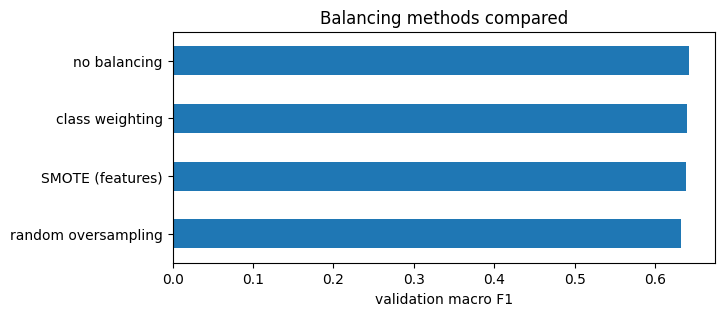

In [ ]:
# per-class F1 for the smallest classes, plus a summary chart
small = ["side_table", "tv_stand", "console_table", "dressing_table"]
pc = pd.DataFrame(per_class, index=classes)
display(pc.loc[small].round(2))

pd.Series(results).sort_values().plot(kind="barh", figsize=(7, 3))
plt.xlabel("validation macro F1"); plt.title("Balancing methods compared"); plt.show()
pc.assign(class_=pc.index).to_csv(f"{DRIVE}/balancing_results.csv", index=False)

**Decision:** All four methods scored within 0.01 macro F1 (no balancing 0.642, class weighting 0.639, SMOTE 0.638, random oversampling 0.633), so the imbalance (about 3:1) does not hurt the model much. The smallest classes already score well (0.67–0.95), and the lowest scores come from look-alike classes. Class weighting is chosen for final training because it is the simplest, changes no data, and still protects the small classes. The test set was not used.